In [1]:
from pathlib import Path
import pandas as pd

pasta_dados = Path("dados")

print("Versão do pandas:", pd.__version__)
print("\nArquivos encontrados:")

for arquivo in pasta_dados.iterdir():
    if arquivo.is_file():
        print("-", arquivo.name)

Versão do pandas: 3.0.6

Arquivos encontrados:
- resultados_cpc_2019.xlsx
- CPC_2023.xlsx
- microdados_censo_da_educacao_superior_2023.zip
- resultado_cpc_2017.csv


In [4]:

# Carregar as três bases do CPC

cpc_2017 = pd.read_csv(
    pasta_dados / "resultado_cpc_2017.csv",
    sep=None,
    engine="python",
    encoding="latin1"
)

cpc_2019 = pd.read_excel(
    pasta_dados / "resultados_cpc_2019.xlsx"
)

cpc_2023 = pd.read_excel(
    pasta_dados / "CPC_2023.xlsx"
)

# Mostrar quantidade de linhas e colunas

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\nCPC {ano}")
    print("Linhas:", base.shape[0])


CPC 2017
Linhas: 10570

CPC 2019
Linhas: 8368

CPC 2023
Linhas: 9812


In [5]:
# Verificar as colunas das três bases

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\n===== CPC {ano} =====")
    print("Quantidade de colunas:", base.shape[1])

    for coluna in base.columns:
        print("-", coluna)



===== CPC 2017 =====
Quantidade de colunas: 38
- Edição
- Código da Área
- Área de Avaliação
- Código da IES
- Nome da IES
- Sigla da IES
- Organização Acadêmica
- Categoria Administrativa
- Código do Curso
- Modalidade de Ensino
- Código do Município
- Município do Curso
- Sigla da UF
- Nº de Concluintes Inscritos
- Nº  de Concluintes Participantes
- Nota Bruta - FG
- Nota Bruta - CE
- Nota Contínua do Enade
- Nº de Concluintes Participantes com nota no Enem
- Percentual de Concluintes participantes com nota no Enem
- Nota Bruta - IDD
- Nota Padronizada - IDD
- Nota Bruta - Organização Didático-Pedagógica
- Nota Padronizada - Organização Didático-Pedagógica
- Nota Bruta - Infraestrutura e Instalações Físicas
- Nota Padronizada - Infraestrutura e Instalações Físicas
- Nota Bruta - Oportunidades de Ampliação da Formação
- Nota Padronizada - Oportunidades de Ampliação da Formação
- Nº de Docentes
- Nota Bruta - Mestres
- Nota Padronizada - Mestres
- Nota Bruta - Doutores
- Nota Padroniz

In [6]:
# Comparar os nomes das colunas dos três anos

colunas = pd.DataFrame({
    "CPC 2017": pd.Series(cpc_2017.columns),
    "CPC 2019": pd.Series(cpc_2019.columns),
    "CPC 2023": pd.Series(cpc_2023.columns)
})

display(colunas)

,CPC 2017,CPC 2019,CPC 2023
0,Edição,Ano,Ano
1,Código da Área,Código da Área,Código da IES
2,Área de Avaliação,Área de Avaliação,Nome da IES
3,Código da IES,Código da IES,Sigla da IES
4,Nome da IES,Nome da IES,Organização Acadêmica
5,Sigla da IES,Sigla da IES,Categoria Administrativa
6,Organização Acadêmica,Organização Acadêmica,Código do Curso
7,Categoria Administrativa,Categoria Administrativa,Código da Área
8,Código do Curso,Código do Curso,Área de Avaliação
9,Modalidade de Ensino,Modalidade de Ensino,Modalidade de Ensino


In [7]:
# Caracterização inicial das três bases

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\n===== CPC {ano} =====")
    print("Registros:", base.shape[0])
    print("Variáveis:", base.shape[1])
    print("Valores ausentes:", base.isna().sum().sum())
    print("Registros duplicados:", base.duplicated().sum())

    print("\nTipos de dados:")
    print(base.dtypes.value_counts())



===== CPC 2017 =====
Registros: 10570
Variáveis: 38
Valores ausentes: 15324
Registros duplicados: 0

Tipos de dados:
str        29
int64       7
float64     2
Name: count, dtype: int64

===== CPC 2019 =====
Registros: 8368
Variáveis: 39
Valores ausentes: 12236
Registros duplicados: 0

Tipos de dados:
float64    22
str         8
int64       7
object      2
Name: count, dtype: int64

===== CPC 2023 =====
Registros: 9812
Variáveis: 39
Valores ausentes: 8226
Registros duplicados: 0

Tipos de dados:
float64    21
str        10
int64       8
Name: count, dtype: int64


In [8]:
print("===== CPC 2023 =====")
print("Registros:", cpc_2023.shape[0])
print("Variáveis:", cpc_2023.shape[1])
print("Valores ausentes:", cpc_2023.isna().sum().sum())
print("Registros duplicados:", cpc_2023.duplicated().sum())
print("\nTipos de dados:")
print(cpc_2023.dtypes.value_counts())

===== CPC 2023 =====
Registros: 9812
Variáveis: 39
Valores ausentes: 8226
Registros duplicados: 0

Tipos de dados:
float64    21
str        10
int64       8
Name: count, dtype: int64


In [9]:
# Verificar as chaves de identificação dos cursos

chaves = ["Código da IES", "Código do Curso"]

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\n===== CPC {ano} =====")

    print("Códigos ausentes:")
    print(base[chaves].isna().sum())

    print(
        "Chaves duplicadas:",
        base.duplicated(subset=chaves).sum()
    )

    print(
        "Cursos identificados:",
        base[chaves].drop_duplicates().shape[0]
    )



===== CPC 2017 =====
Códigos ausentes:
Código da IES      0
Código do Curso    0
dtype: int64
Chaves duplicadas: 0
Cursos identificados: 10570

===== CPC 2019 =====
Códigos ausentes:


KeyError: "None of [Index(['Código da IES', 'Código do Curso'], dtype='str')] are in the [columns]"

In [10]:

# Limpar espaços e caracteres invisíveis dos nomes das colunas

for base in [cpc_2017, cpc_2019, cpc_2023]:
    base.columns = (
        base.columns
        .str.replace("\ufeff", "", regex=False)
        .str.replace("\xa0", " ", regex=False)
        .str.strip()
    )

# Conferir se as colunas foram encontradas
chaves = ["Código da IES", "Código do Curso"]

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\nCPC {ano}")
    print("Colunas encontradas:",
          [c for c in chaves if c in base.columns])
    print("Colunas ausentes:",
          [c for c in chaves if c not in base.columns])


CPC 2017
Colunas encontradas: ['Código da IES', 'Código do Curso']
Colunas ausentes: []

CPC 2019
Colunas encontradas: ['Código da IES', 'Código do Curso']
Colunas ausentes: []

CPC 2023
Colunas encontradas: ['Código da IES', 'Código do Curso']
Colunas ausentes: []


In [13]:
# Verificar os códigos de identificação dos cursos

chaves = ["Código da IES", "Código do Curso"]

for ano, base in [
    (2017, cpc_2017),
    (2019, cpc_2019),
    (2023, cpc_2023)
]:
    print(f"\n===== CPC {ano} =====")

    print("Códigos ausentes:")
    print(base[chaves].isna().sum())

    print(
        "Chaves duplicadas:",
        base.duplicated(subset=chaves).sum()
    )

    print(
               "Cursos identificados:",
        base[chaves].drop_duplicates().shape[0]
    )


===== CPC 2017 =====
Códigos ausentes:
Código da IES      0
Código do Curso    0
dtype: int64
Chaves duplicadas: 0
Cursos identificados: 10570

===== CPC 2019 =====
Códigos ausentes:
Código da IES      0
Código do Curso    0
dtype: int64
Chaves duplicadas: 0
Cursos identificados: 8368

===== CPC 2023 =====
Códigos ausentes:
Código da IES      0
Código do Curso    0
dtype: int64
Chaves duplicadas: 0
Cursos identificados: 9812


In [14]:
# Padronizar os códigos para permitir o cruzamento

chaves = ["Código da IES", "Código do Curso"]

for base in [cpc_2017, cpc_2019, cpc_2023]:
    for coluna in chaves:
        base[coluna] = pd.to_numeric(
            base[coluna], errors="coerce"
        ).astype("Int64")

# Identificar os cursos presentes nos três anos

cursos_2017 = cpc_2017[chaves].drop_duplicates()
cursos_2019 = cpc_2019[chaves].drop_duplicates()
cursos_2023 = cpc_2023[chaves].drop_duplicates()

cursos_comuns = (
    cursos_2017
    .merge(cursos_2019, on=chaves, how="inner")
    .merge(cursos_2023, on=chaves, how="inner")
)

print("Cursos presentes nos três ciclos:",
      len(cursos_comuns))

# Conferir também as correspondências entre dois anos

print(
    "Cursos presentes em 2017 e 2023:",
    len(cursos_2017.merge(cursos_2023, on=chaves))
)

print(
    "Cursos presentes em 2019 e 2023:",
    len(cursos_2019.merge(cursos_2023, on=chaves))
)


Cursos presentes nos três ciclos: 2185
Cursos presentes em 2017 e 2023: 2197
Cursos presentes em 2019 e 2023: 6594


In [15]:
# Selecionar os cursos presentes nos três ciclos

bases = {
    2017: cpc_2017,
    2019: cpc_2019,
    2023: cpc_2023
}

for ano, base in bases.items():
    cursos = base.merge(
        cursos_comuns,
        on=chaves,
        how="inner"
    )

    print(f"\n===== CPC {ano} =====")
    print("Cursos comuns:", len(cursos))

    print("\nModalidades de ensino:")
    print(
        cursos["Modalidade de Ensino"]
        .value_counts(dropna=False)
    )

    print("\nÁreas de avaliação distintas:")
    print(cursos["Código da Área"].nunique())



===== CPC 2017 =====
Cursos comuns: 2185

Modalidades de ensino:
Modalidade de Ensino
Educação Presencial     2174
Educação a Distância      11
Name: count, dtype: int64

Áreas de avaliação distintas:
13

===== CPC 2019 =====
Cursos comuns: 2185

Modalidades de ensino:
Modalidade de Ensino
Educação Presencial     2174
Educação a Distância      11
Name: count, dtype: int64

Áreas de avaliação distintas:
12

===== CPC 2023 =====
Cursos comuns: 2185

Modalidades de ensino:
Modalidade de Ensino
Educação Presencial     2174
Educação a Distância      11
Name: count, dtype: int64

Áreas de avaliação distintas:
12


In [16]:
# Resumo dos cursos presentes nos três ciclos

for ano, base in bases.items():
    cursos = base.merge(cursos_comuns, on=chaves)

    modalidades = cursos["Modalidade de Ensino"].astype(str).str.strip()

    print(
        ano,
        "| Total:", len(cursos),
        "| Presenciais:", (modalidades == "Educação Presencial").sum(),
        "| EaD:", (modalidades == "Educação a Distância").sum(),
        "| Áreas:", cursos["Código da Área"].nunique()
    )

2017 | Total: 2185 | Presenciais: 2174 | EaD: 11 | Áreas: 13
2019 | Total: 2185 | Presenciais: 2174 | EaD: 11 | Áreas: 12
2023 | Total: 2185 | Presenciais: 2174 | EaD: 11 | Áreas: 12


In [18]:
# Comparar modalidade e área dos mesmos cursos

comparacao = cursos_comuns.copy()

for ano, base in bases.items():
    dados_ano = base[
        chaves + ["Modalidade de Ensino", "Código da Área"]
    ].copy()

    dados_ano = dados_ano.rename(columns={
        "Modalidade de Ensino": f"Modalidade_{ano}",
        "Código da Área": f"Area_{ano}"
    })

    comparacao = comparacao.merge(
        dados_ano,
        on=chaves,
        how="left"
    )

In [19]:
# Verificar se a modalidade é igual nos três ciclos
modalidade_igual = (
    (comparacao["Modalidade_2017"] == comparacao["Modalidade_2019"]) &
    (comparacao["Modalidade_2019"] == comparacao["Modalidade_2023"])
)

# Verificar se o código da área é igual nos três ciclos
area_igual = (
    (comparacao["Area_2017"].astype(str) == comparacao["Area_2019"].astype(str)) &
    (comparacao["Area_2019"].astype(str) == comparacao["Area_2023"].astype(str))
)

print("Cursos com mesma modalidade:", modalidade_igual.sum())
print("Cursos com mudança de modalidade:", (~modalidade_igual).sum())

print("Cursos com mesmo código de área:", area_igual.sum())
print("Cursos com códigos de área diferentes:", (~area_igual).sum())


Cursos com mesma modalidade: 2185
Cursos com mudança de modalidade: 0
Cursos com mesmo código de área: 2094
Cursos com códigos de área diferentes: 91


In [20]:
# Verificar disponibilidade do CPC Contínuo

nomes_cpc = {
    2017: "CPC Contínuo",
    2019: "CPC (Contínuo)",
    2023: "CPC (Contínuo)"
}

dados_cpc = cursos_comuns.copy()

for ano, base in bases.items():
    coluna = nomes_cpc[ano]

    auxiliar = base[
        chaves + [coluna]
    ].copy()

    auxiliar = auxiliar.rename(
        columns={coluna: f"CPC_{ano}"}
    )

    dados_cpc = dados_cpc.merge(
        auxiliar,
        on=chaves,
        how="left"
    )

# Converter valores para números
for ano in [2017, 2019, 2023]:
    coluna = f"CPC_{ano}"

    dados_cpc[coluna] = pd.to_numeric(
        dados_cpc[coluna]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Contar cursos com CPC disponível nos três anos
cpc_completo = dados_cpc[
    ["CPC_2017", "CPC_2019", "CPC_2023"]
].notna().all(axis=1)

print("Cursos presentes nos três ciclos:", len(dados_cpc))
print("Cursos com CPC nos três anos:", cpc_completo.sum())
print("Cursos com algum CPC ausente:", (~cpc_completo).sum())


Cursos presentes nos três ciclos: 2185
Cursos com CPC nos três anos: 2068
Cursos com algum CPC ausente: 117


In [21]:
# Combinar os critérios de seleção

amostra = comparacao.merge(
    dados_cpc,
    on=chaves,
    how="inner"
)

# Selecionar cursos presenciais nos três anos
presencial = (
    (amostra["Modalidade_2017"].str.strip() == "Educação Presencial") &
    (amostra["Modalidade_2019"].str.strip() == "Educação Presencial") &
    (amostra["Modalidade_2023"].str.strip() == "Educação Presencial")
)

# Verificar CPC completo
cpc_valido = amostra[
    ["CPC_2017", "CPC_2019", "CPC_2023"]
].notna().all(axis=1)

# Verificar igualdade dos códigos de área
mesma_area = (
    (amostra["Area_2017"].astype(str) == amostra["Area_2019"].astype(str)) &
    (amostra["Area_2019"].astype(str) == amostra["Area_2023"].astype(str))
)

print("Cursos com CPC completo:", cpc_valido.sum())
print("Cursos presenciais com CPC completo:",
      (presencial & cpc_valido).sum())
print("Cursos com CPC completo e mesma área:",
      (cpc_valido & mesma_area).sum())
print("Cursos presenciais, CPC completo e mesma área:",
      (presencial & cpc_valido & mesma_area).sum())


Cursos com CPC completo: 2068
Cursos presenciais com CPC completo: 2058
Cursos com CPC completo e mesma área: 1983
Cursos presenciais, CPC completo e mesma área: 1973


In [22]:
from zipfile import ZipFile

arquivo_zip = pasta_dados / "microdados_censo_da_educacao_superior_2023.zip"

with ZipFile(arquivo_zip) as zip_censo:
    arquivos = zip_censo.namelist()

print("Quantidade de arquivos no ZIP:", len(arquivos))

print("\nArquivos CSV encontrados:")
for nome in arquivos:
    if nome.lower().endswith(".csv"):
        print("-", nome)


Quantidade de arquivos no ZIP: 22

Arquivos CSV encontrados:
- microdados_censo_da_educacao_superior_2023/dados/MICRODADOS_CADASTRO_CURSOS_2023.CSV
- microdados_censo_da_educacao_superior_2023/dados/MICRODADOS_ED_SUP_IES_2023.CSV


In [23]:
from zipfile import ZipFile
import pandas as pd

arquivo_zip = pasta_dados / "microdados_censo_da_educacao_superior_2023.zip"

nome_csv = (
    "microdados_censo_da_educacao_superior_2023/"
    "dados/MICRODADOS_CADASTRO_CURSOS_2023.CSV"
)

# Ler apenas as primeiras 5 linhas
with ZipFile(arquivo_zip) as zip_censo:
    with zip_censo.open(nome_csv) as arquivo:
        amostra_censo = pd.read_csv(
            arquivo,
            sep=";",
            encoding="latin1",
            nrows=5,
            low_memory=False
        )

print("Linhas carregadas:", len(amostra_censo))
print("Quantidade de colunas:", len(amostra_censo.columns))

print("\nPrimeiras 15 colunas:")
print(amostra_censo.columns.tolist()[:15])


Linhas carregadas: 5
Quantidade de colunas: 202

Primeiras 15 colunas:
['NU_ANO_CENSO', 'NO_REGIAO', 'CO_REGIAO', 'NO_UF', 'SG_UF', 'CO_UF', 'NO_MUNICIPIO', 'CO_MUNICIPIO', 'IN_CAPITAL', 'TP_DIMENSAO', 'TP_ORGANIZACAO_ACADEMICA', 'TP_REDE', 'TP_CATEGORIA_ADMINISTRATIVA', 'IN_COMUNITARIA', 'IN_CONFESSIONAL']


In [24]:
# Identificar as colunas importantes do Censo

termos = [
    "CO_IES",
    "CO_CURSO",
    "TP_MODALIDADE",
    "TP_DIMENSAO",
    "QT_MAT",
    "QT_CONC"
]

colunas_encontradas = [
    coluna for coluna in amostra_censo.columns
    if any(termo in coluna for termo in termos)
]

print("Colunas encontradas:")
for coluna in colunas_encontradas:
    print("-", coluna)


Colunas encontradas:
- TP_DIMENSAO
- CO_IES
- CO_CURSO
- TP_MODALIDADE_ENSINO
- QT_MAT
- QT_MAT_FEM
- QT_MAT_MASC
- QT_MAT_DIURNO
- QT_MAT_NOTURNO
- QT_MAT_0_17
- QT_MAT_18_24
- QT_MAT_25_29
- QT_MAT_30_34
- QT_MAT_35_39
- QT_MAT_40_49
- QT_MAT_50_59
- QT_MAT_60_MAIS
- QT_MAT_BRANCA
- QT_MAT_PRETA
- QT_MAT_PARDA
- QT_MAT_AMARELA
- QT_MAT_INDIGENA
- QT_MAT_CORND
- QT_CONC
- QT_CONC_FEM
- QT_CONC_MASC
- QT_CONC_DIURNO
- QT_CONC_NOTURNO
- QT_CONC_0_17
- QT_CONC_18_24
- QT_CONC_25_29
- QT_CONC_30_34
- QT_CONC_35_39
- QT_CONC_40_49
- QT_CONC_50_59
- QT_CONC_60_MAIS
- QT_CONC_BRANCA
- QT_CONC_PRETA
- QT_CONC_PARDA
- QT_CONC_AMARELA
- QT_CONC_INDIGENA
- QT_CONC_CORND
- QT_MAT_NACBRAS
- QT_MAT_NACESTRANG
- QT_CONC_NACBRAS
- QT_CONC_NACESTRANG
- QT_MAT_DEFICIENTE
- QT_CONC_DEFICIENTE
- QT_MAT_FINANC
- QT_MAT_FINANC_REEMB
- QT_MAT_FIES
- QT_MAT_RPFIES
- QT_MAT_FINANC_REEMB_OUTROS
- QT_MAT_FINANC_NREEMB
- QT_MAT_PROUNII
- QT_MAT_PROUNIP
- QT_MAT_NRPFIES
- QT_MAT_FINANC_NREEMB_OUTROS
- QT_CONC_FIN

In [26]:
# Selecionar as variáveis necessárias do Censo

colunas_censo = [
    "CO_IES",
    "CO_CURSO",
    "TP_DIMENSAO",
    "TP_MODALIDADE_ENSINO",
    "QT_MAT",
    "QT_CONC"
]

# Carregar apenas essas colunas
with ZipFile(arquivo_zip) as zip_censo:
    with zip_censo.open(nome_csv) as arquivo:
        censo_2023 = pd.read_csv(
            arquivo,
            sep=";",
            encoding="latin1",
            usecols=colunas_censo,
            low_memory=False
             )

print("Registros do Censo:", len(censo_2023))

# Selecionar cursos presenciais de graduação
censo_presencial = censo_2023[
    (censo_2023["TP_DIMENSAO"] == 1) &
    (censo_2023["TP_MODALIDADE_ENSINO"] == 1)
].copy()

print("Registros presenciais de graduação:",
      len(censo_presencial))

# Conferir possíveis duplicidades das chaves
print(
    "Chaves duplicadas no Censo filtrado:",
    censo_presencial.duplicated(
        subset=["CO_IES", "CO_CURSO"]
    ).sum()
)


Registros do Censo: 671610
Registros presenciais de graduação: 35739
Chaves duplicadas no Censo filtrado: 0


In [27]:
# Preparar as chaves de integração
censo_presencial["CO_IES"] = pd.to_numeric(
    censo_presencial["CO_IES"], errors="coerce"
).astype("Int64")

censo_presencial["CO_CURSO"] = pd.to_numeric(
    censo_presencial["CO_CURSO"], errors="coerce"
).astype("Int64")

# Selecionar cursos presenciais no CPC 2023
cpc_presencial = cpc_2023[
    cpc_2023["Modalidade de Ensino"]
    .astype(str).str.strip()
    .eq("Educação Presencial")
].copy()

# Cruzar as duas bases
integracao = cpc_presencial.merge(
    censo_presencial,
    left_on=["Código da IES", "Código do Curso"],
    right_on=["CO_IES", "CO_CURSO"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

# Resumo da integração
print("Cursos presenciais no CPC 2023:", len(cpc_presencial))
print("Cursos encontrados no Censo:",
      (integracao["_merge"] == "both").sum())
print("Cursos não encontrados:",
      (integracao["_merge"] == "left_only").sum())

print("Percentual de correspondência:",
      round(
          (integracao["_merge"] == "both").mean() * 100, 2
      ), "%")


Cursos presenciais no CPC 2023: 9120
Cursos encontrados no Censo: 9076
Cursos não encontrados: 44
Percentual de correspondência: 99.52 %


In [28]:
# Criar a pasta de resultados, caso necessário
pasta_resultados = Path("resultados")
pasta_resultados.mkdir(exist_ok=True)

# Salvar a base integrada de 2023
integracao.to_csv(
    pasta_resultados / "cpc_censo_2023.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

# Salvar a amostra longitudinal preliminar
amostra_final = amostra[
    presencial & cpc_valido & mesma_area
].copy()

amostra_final.to_csv(
    pasta_resultados / "amostra_longitudinal_preliminar.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

print("Base CPC + Censo 2023 salva:", len(integracao))
print("Amostra longitudinal preliminar salva:", len(amostra_final))
print("Arquivos salvos na pasta resultados.")


Base CPC + Censo 2023 salva: 9120
Amostra longitudinal preliminar salva: 1973
Arquivos salvos na pasta resultados.


In [29]:
# Identificar os indicadores disponíveis em cada ano

palavras_chave = [
    "Enade", "IDD", "Mestre", "Doutor",
    "Regime", "Organização", "Infraestrutura",
    "Oportunidades"
]

for ano, base in bases.items():
    print(f"\n{'=' * 15} CPC {ano} {'=' * 15}")

    for coluna in base.columns:
        if any(
            palavra.lower() in coluna.lower()
            for palavra in palavras_chave
        ):
            print(coluna)


=============== CPC 2017 ===============
Organização Acadêmica
Nota Contínua do Enade
Nota Bruta - IDD
Nota Padronizada - IDD
Nota Bruta - Organização Didático-Pedagógica
Nota Padronizada - Organização Didático-Pedagógica
Nota Bruta - Infraestrutura e Instalações Físicas
Nota Padronizada - Infraestrutura e Instalações Físicas
Nota Bruta - Oportunidades de Ampliação da Formação
Nota Padronizada - Oportunidades de Ampliação da Formação
Nota Bruta - Mestres
Nota Padronizada - Mestres
Nota Bruta - Doutores
Nota Padronizada - Doutores
Nota Bruta - Regime de Trabalho
Nota Padronizada - Regime de Trabalho

=============== CPC 2019 ===============
Organização Acadêmica
Conceito Enade (Contínuo)
Nota Bruta - IDD
Nota Padronizada - IDD
Nota Bruta – Organização Didático-Pedagógica
Nota Padronizada - Organização Didático-Pedagógica
Nota Bruta – Infraestrutura e Instalações Físicas
Nota Padronizada - Infraestrutura e Instalações Físicas
Nota Bruta - Mestres
Nota Padronizada - Mestres
Nota Bruta - 

In [30]:
# Conferir os nomes completos das colunas dos três anos

for ano, base in bases.items():
    print(f"\n===== CPC {ano} =====")
    for numero, coluna in enumerate(base.columns, start=1):
        print(f"{numero:02d}. {coluna}")


===== CPC 2017 =====
01. Edição
02. Código da Área
03. Área de Avaliação
04. Código da IES
05. Nome da IES
06. Sigla da IES
07. Organização Acadêmica
08. Categoria Administrativa
09. Código do Curso
10. Modalidade de Ensino
11. Código do Município
12. Município do Curso
13. Sigla da UF
14. Nº de Concluintes Inscritos
15. Nº  de Concluintes Participantes
16. Nota Bruta - FG
17. Nota Bruta - CE
18. Nota Contínua do Enade
19. Nº de Concluintes Participantes com nota no Enem
20. Percentual de Concluintes participantes com nota no Enem
21. Nota Bruta - IDD
22. Nota Padronizada - IDD
23. Nota Bruta - Organização Didático-Pedagógica
24. Nota Padronizada - Organização Didático-Pedagógica
25. Nota Bruta - Infraestrutura e Instalações Físicas
26. Nota Padronizada - Infraestrutura e Instalações Físicas
27. Nota Bruta - Oportunidades de Ampliação da Formação
28. Nota Padronizada - Oportunidades de Ampliação da Formação
29. Nº de Docentes
30. Nota Bruta - Mestres
31. Nota Padronizada - Mestres
32.

In [31]:
# Mostrar somente os indicadores necessários, sem cortar a saída

for ano, base in bases.items():
    print(f"\n===== CPC {ano} =====")
    colunas = [
        coluna for coluna in base.columns
        if any(termo in coluna.lower() for termo in [
            "enade", "idd", "mestres", "doutores",
            "regime de trabalho", "didático-pedagógica",
            "infraestrutura", "oportunidades", "cpc"
        ])
    ]
    print("\n".join(colunas))


===== CPC 2017 =====
Nota Contínua do Enade
Nota Bruta - IDD
Nota Padronizada - IDD
Nota Bruta - Organização Didático-Pedagógica
Nota Padronizada - Organização Didático-Pedagógica
Nota Bruta - Infraestrutura e Instalações Físicas
Nota Padronizada - Infraestrutura e Instalações Físicas
Nota Bruta - Oportunidades de Ampliação da Formação
Nota Padronizada - Oportunidades de Ampliação da Formação
Nota Bruta - Mestres
Nota Padronizada - Mestres
Nota Bruta - Doutores
Nota Padronizada - Doutores
Nota Bruta - Regime de Trabalho
Nota Padronizada - Regime de Trabalho
CPC Contínuo
CPC Faixa

===== CPC 2019 =====
Conceito Enade (Contínuo)
Nota Bruta - IDD
Nota Padronizada - IDD
Nota Bruta – Organização Didático-Pedagógica
Nota Padronizada - Organização Didático-Pedagógica
Nota Bruta – Infraestrutura e Instalações Físicas
Nota Padronizada - Infraestrutura e Instalações Físicas
Nota Bruta - Mestres
Nota Padronizada - Mestres
Nota Bruta - Doutores
Nota Padronizada - Doutores
Nota Bruta – Regime de T

In [32]:
import unicodedata
import re

# Padronizar os nomes para localizar indicadores equivalentes
def normalizar_nome(nome):
    nome = unicodedata.normalize("NFKD", str(nome))
    nome = "".join(c for c in nome if not unicodedata.combining(c))
    nome = nome.lower().replace("–", "-").replace("—", "-")
    return re.sub(r"\s+", " ", nome).strip()

# Indicadores históricos que queremos reunir
indicadores = {
    "Enade": ["nota continua do enade", "conceito enade (continuo)"],
    "IDD": ["nota padronizada - idd"],
    "Mestres": ["nota padronizada - mestres"],
    "Doutores": ["nota padronizada - doutores"],
    "Regime_Trabalho": ["nota padronizada - regime de trabalho"],
    "Organizacao_Didatica": [
        "nota padronizada - organizacao didatico-pedagogica"
    ],
    "Infraestrutura": [
        "nota padronizada - infraestrutura e instalacoes fisicas"
    ],
    "Oportunidades": [
        "nota padronizada - oportunidades de ampliacao da formacao"
    ]
}

base_enriquecida = amostra_final.copy()

for ano, base in bases.items():
    mapa_colunas = {
        normalizar_nome(coluna): coluna
        for coluna in base.columns
    }

    selecionadas = chaves.copy()
    renomear = {}

    for indicador, alternativas in indicadores.items():
        encontrada = next(
            (mapa_colunas[normalizar_nome(nome)]
             for nome in alternativas
             if normalizar_nome(nome) in mapa_colunas),
            None
        )

        if encontrada:
            selecionadas.append(encontrada)
            renomear[encontrada] = f"{indicador}_{ano}"
        else:
            print(f"ATENÇÃO: {indicador} não encontrado em {ano}")

    auxiliar = base[selecionadas].rename(columns=renomear)

    base_enriquecida = base_enriquecida.merge(
        auxiliar,
        on=chaves,
        how="left",
        validate="one_to_one"
    )

# Converter indicadores em números
colunas_indicadores = [
    coluna for coluna in base_enriquecida.columns
    if any(coluna.startswith(f"{nome}_") for nome in indicadores)
]

for coluna in colunas_indicadores:
    base_enriquecida[coluna] = pd.to_numeric(
        base_enriquecida[coluna]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Salvar o arquivo
base_enriquecida.to_csv(
    pasta_resultados / "base_longitudinal_enriquecida.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

print("\nCursos na base:", len(base_enriquecida))
print("Indicadores históricos encontrados:", len(colunas_indicadores))
print("Arquivo salvo: base_longitudinal_enriquecida.csv")


ATENÇÃO: Oportunidades não encontrado em 2019
ATENÇÃO: Oportunidades não encontrado em 2023

Cursos na base: 1973
Indicadores históricos encontrados: 22
Arquivo salvo: base_longitudinal_enriquecida.csv


In [33]:
# Localizar todas as colunas relacionadas a oportunidades e formação

for ano in [2019, 2023]:
    print(f"\n===== CPC {ano} =====")

    for coluna in bases[ano].columns:
        nome = normalizar_nome(coluna)

        if "oportun" in nome or "formacao" in nome:
            print(repr(coluna))


===== CPC 2019 =====
'Nota Bruta – Oportunidade de Ampliação da Formação'
'Nota Padronizada - Oportunidade de Ampliação da Formação'

===== CPC 2023 =====
'Nota Bruta – Oportunidade de Ampliação da Formação'
'Nota Padronizada - Oportunidade de Ampliação da Formação'


In [34]:
# Acrescentar o indicador de oportunidades de 2019 e 2023

for ano in [2019, 2023]:
    coluna_origem = "Nota Padronizada - Oportunidade de Ampliação da Formação"
    coluna_destino = f"Oportunidades_{ano}"

    auxiliar = bases[ano][chaves + [coluna_origem]].copy()
    auxiliar = auxiliar.rename(columns={coluna_origem: coluna_destino})

    base_enriquecida = base_enriquecida.merge(
        auxiliar,
        on=chaves,
        how="left",
        validate="one_to_one"
    )

    base_enriquecida[coluna_destino] = pd.to_numeric(
        base_enriquecida[coluna_destino]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Salvar novamente a base corrigida
base_enriquecida.to_csv(
    pasta_resultados / "base_longitudinal_enriquecida.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

print("Cursos:", len(base_enriquecida))
print("Indicadores históricos:", len([
    coluna for coluna in base_enriquecida.columns
    if any(coluna.startswith(f"{nome}_") for nome in indicadores)
]))
print("Arquivo atualizado com sucesso!")


Cursos: 1973
Indicadores históricos: 24
Arquivo atualizado com sucesso!


In [36]:

# Verificar valores ausentes dos 24 indicadores históricos

colunas_historicas = [
    f"{indicador}_{ano}"
    for indicador in indicadores
    for ano in [2017, 2019, 2023]
]

resumo_ausentes = pd.DataFrame({
    "Valores ausentes": base_enriquecida[colunas_historicas].isna().sum(),
    "Percentual (%)": (
        base_enriquecida[colunas_historicas].isna().mean() * 100
    ).round(2)
})

print("===== VALORES AUSENTES POR INDICADOR =====")
print(resumo_ausentes.to_string())

===== VALORES AUSENTES POR INDICADOR =====
                           Valores ausentes  Percentual (%)
Enade_2017                                0            0.00
Enade_2019                                0            0.00
Enade_2023                                0            0.00
IDD_2017                                  0            0.00
IDD_2019                                  8            0.41
IDD_2023                                 60            3.04
Mestres_2017                              0            0.00
Mestres_2019                              0            0.00
Mestres_2023                              0            0.00
Doutores_2017                             0            0.00
Doutores_2019                             0            0.00
Doutores_2023                             0            0.00
Regime_Trabalho_2017                      0            0.00
Regime_Trabalho_2019                      0            0.00
Regime_Trabalho_2023                      0            0.

In [37]:
# Conferência final da amostra longitudinal

completos = base_enriquecida[
    colunas_historicas
].notna().all(axis=1)

print("Total de cursos:", len(base_enriquecida))
print("Cursos com todos os indicadores:", completos.sum())
print("Cursos com alguma ausência:", (~completos).sum())
print("Percentual completo:", round(completos.mean() * 100, 2), "%")


Total de cursos: 1973
Cursos com todos os indicadores: 1907
Cursos com alguma ausência: 66
Percentual completo: 96.65 %


In [38]:
import pandas as pd
from pathlib import Path

# Procurar a base longitudinal na pasta do projeto
arquivos = list(Path.cwd().rglob("base_longitudinal_enriquecida.csv"))

if arquivos:
    caminho = arquivos[0]
    print("Arquivo encontrado:", caminho)

    df = pd.read_csv(caminho, sep=None, engine="python")
    print("Quantidade de cursos:", df.shape[0])
    print("Quantidade de colunas:", df.shape[1])

    display(df.head())
else:
    print("Arquivo não encontrado. Precisamos verificar onde ele está salvo.")


Arquivo encontrado: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados\base_longitudinal_enriquecida.csv
Quantidade de cursos: 1973
Quantidade de colunas: 35


,﻿Código da IES,Código do Curso,Modalidade_2017,Area_2017,Modalidade_2019,Area_2019,Modalidade_2023,Area_2023,CPC_2017,CPC_2019,...,Infraestrutura_2019,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2019,Oportunidades_2023
0,1,44,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.8917,3.216,...,0.450,4.191,3.488,3.750,2.917,5.0,2.640,1.396,2.476,3.440
1,2,132,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,3.2611,3.220,...,1.335,4.231,4.144,4.922,4.501,5.0,3.111,2.933,3.287,3.920
2,2,1138293,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.9394,3.194,...,0.854,4.194,4.187,4.907,4.519,5.0,3.120,2.866,3.166,3.860
3,3,99444,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.9489,2.973,...,0.959,3.920,3.623,4.107,3.571,5.0,1.445,1.190,2.351,2.550
4,4,122640,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.4111,2.663,...,1.491,3.812,3.465,2.530,1.951,5.0,2.501,2.409,1.145,2.014


In [39]:
# Remover caracteres invisíveis e espaços dos nomes das colunas
df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()

# Conferir as informações gerais
print("Quantidade de cursos:", len(df))
print("Quantidade de colunas:", len(df.columns))

print("\nNomes das colunas:")
for coluna in df.columns:
    print(coluna)

print("\nValores ausentes por coluna:")
ausentes = df.isna().sum()
print(ausentes[ausentes > 0])

print("\nTipos das variáveis:")
print(df.dtypes)

Quantidade de cursos: 1973
Quantidade de colunas: 35

Nomes das colunas:
Código da IES
Código do Curso
Modalidade_2017
Area_2017
Modalidade_2019
Area_2019
Modalidade_2023
Area_2023
CPC_2017
CPC_2019
CPC_2023
Enade_2017
IDD_2017
Mestres_2017
Doutores_2017
Regime_Trabalho_2017
Organizacao_Didatica_2017
Infraestrutura_2017
Oportunidades_2017
Enade_2019
IDD_2019
Mestres_2019
Doutores_2019
Regime_Trabalho_2019
Organizacao_Didatica_2019
Infraestrutura_2019
Enade_2023
IDD_2023
Mestres_2023
Doutores_2023
Regime_Trabalho_2023
Organizacao_Didatica_2023
Infraestrutura_2023
Oportunidades_2019
Oportunidades_2023

Valores ausentes por coluna:
IDD_2019                      8
IDD_2023                     60
Organizacao_Didatica_2023     2
Infraestrutura_2023           2
Oportunidades_2023            2
dtype: int64

Tipos das variáveis:
Código da IES                  int64
Código do Curso                int64
Modalidade_2017                  str
Area_2017                      int64
Modalidade_2019     

In [40]:
# 1. Valores ausentes
print("VALORES AUSENTES:")
ausentes = df.isna().sum()
print(ausentes[ausentes > 0].to_string())

# 2. Verificar duplicações
duplicados = df.duplicated(
    subset=["Código da IES", "Código do Curso"]
).sum()

print("\nCursos duplicados:", duplicados)

# 3. Verificar áreas de avaliação
print("\nÁREAS DE AVALIAÇÃO:")
print(df["Area_2023"].value_counts().sort_index().to_string())

# 4. Conferir tipos dos indicadores
indicadores = df.select_dtypes(include="number").columns
print("\nQuantidade de colunas numéricas:", len(indicadores))

VALORES AUSENTES:
IDD_2019                      8
IDD_2023                     60
Organizacao_Didatica_2023     2
Infraestrutura_2023           2
Oportunidades_2023            2

Cursos duplicados: 0

ÁREAS DE AVALIAÇÃO:
Area_2023
21      268
5710    461
5806    239
5814    102
5902    253
6002     55
6008    108
6208    321
6307    117
6405     49

Quantidade de colunas numéricas: 32


In [41]:
# Conferir a estrutura dos identificadores institucionais

print("Quantidade de instituições na base:")
print(df["Código da IES"].nunique())

print("\nPrimeiros códigos de instituições:")
print(
    sorted(df["Código da IES"].dropna().unique())[:20]
)

print("\nQuantidade de cursos por instituição:")
print(
    df["Código da IES"]
    .value_counts()
    .head(15)
    .to_string()
)

Quantidade de instituições na base:
535

Primeiros códigos de instituições:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21)]

Quantidade de cursos por instituição:
Código da IES
322    78
163    33
588    28
56     21
338    15
57     14
585    13
589    13
598    13
4      12
8      12
13     12
54     12
569    12
586    12


In [42]:
from pathlib import Path

# Procurar arquivos que possam conter a identificação das instituições
pasta_projeto = Path.cwd()

arquivos = [
    p for p in pasta_projeto.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".csv", ".xlsx", ".xls"]
    and (
        "censo" in p.name.lower()
        or "ies" in p.name.lower()
        or "institu" in p.name.lower()
    )
]

print("Arquivos encontrados:\n")

for arquivo in arquivos:
    print(arquivo.relative_to(pasta_projeto))


Arquivos encontrados:

resultados\cpc_censo_2023.csv


In [43]:
# Abrir o arquivo integrado CPC + Censo 2023
caminho_censo = Path("resultados/cpc_censo_2023.csv")

df_censo = pd.read_csv(
    caminho_censo,
    sep=None,
    engine="python",
    encoding="utf-8-sig",
    low_memory=False
)


ValueError: The 'low_memory' option is not supported with the 'python' engine

In [44]:
df_censo = pd.read_csv(
    caminho_censo,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print("Dimensões:", df_censo.shape)

print("\nColunas relacionadas à instituição:")
colunas_ies = [
    coluna for coluna in df_censo.columns
    if any(termo in coluna.lower()
           for termo in ["ies", "institui", "mantenedora", "sigla"])
]

for coluna in colunas_ies:
    print(coluna)


OSError: [Errno 22] Invalid argument: 'resultados\\cpc_censo_2023.csv'

In [45]:
# Localizar automaticamente o arquivo integrado
caminho_censo = next(
    Path.cwd().rglob("cpc_censo_2023.csv")
)

print("Arquivo encontrado:", caminho_censo)

# Carregar os dados
df_censo = pd.read_csv(
    caminho_censo,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print("Dimensões:", df_censo.shape)

# Procurar colunas relacionadas às instituições
colunas_ies = [
    coluna for coluna in df_censo.columns
    if any(
        termo in coluna.lower()
        for termo in ["ies", "institui", "mantenedora", "sigla"]
    )
]

print("\nColunas relacionadas às instituições:")
for coluna in colunas_ies:
    print(coluna)


Arquivo encontrado: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados\cpc_censo_2023.csv
Dimensões: (9120, 46)

Colunas relacionadas às instituições:
Código da IES
Nome da IES
Sigla da IES
Sigla da UF
CO_IES


In [46]:
# Localizar a PUC-Rio pelo nome ou pela sigla
puc = df_censo[
    df_censo["Nome da IES"].astype(str).str.contains(
        "Pontifícia Universidade Católica do Rio de Janeiro",
        case=False,
        na=False
    )
    |
    df_censo["Sigla da IES"].astype(str).str.contains(
        "PUC-Rio",
        case=False,
        na=False
    )
]

# Mostrar as instituições encontradas
print("Identificação da PUC-Rio:")
display(
    puc[["Código da IES", "Nome da IES", "Sigla da IES"]]
    .drop_duplicates()
)

# Mostrar quantidade de cursos no arquivo integrado
print("\nRegistros da PUC-Rio no CPC/Censo 2023:", len(puc))


Identificação da PUC-Rio:


,Código da IES,Nome da IES,Sigla da IES
1299,528,PONTIFÍCIA UNIVERSIDADE CATÓLICA DO RIO DE JAN...,PUC-RIO



Registros da PUC-Rio no CPC/Censo 2023: 8


In [47]:
# Selecionar os cursos da PUC-Rio na base longitudinal
df_puc = df[df["Código da IES"] == 528].copy()

print("Cursos da PUC-Rio na base longitudinal:", len(df_puc))

# Mostrar os códigos dos cursos e suas áreas de avaliação
display(
    df_puc[
        [
            "Código da IES",
            "Código do Curso",
            "Area_2017",
            "Area_2019",
            "Area_2023"
        ]
    ].sort_values("Código do Curso")
)

print("\nQuantidade de áreas distintas da PUC-Rio:")
print(df_puc["Area_2023"].nunique())

print("\nDistribuição dos cursos por área:")
print(df_puc["Area_2023"].value_counts().sort_index())

Cursos da PUC-Rio na base longitudinal: 8


,Código da IES,Código do Curso,Area_2017,Area_2019,Area_2023
1168,528,23702,5902,5902,5902
441,528,29445,5710,5710,5710
815,528,29446,5806,5806,5806
1003,528,32655,5814,5814,5814
1423,528,32975,6008,6008,6008
1592,528,44431,6208,6208,6208
135,528,59962,21,21,21
1845,528,70523,6307,6307,6307



Quantidade de áreas distintas da PUC-Rio:
8

Distribuição dos cursos por área:
Area_2023
21      1
5710    1
5806    1
5814    1
5902    1
6008    1
6208    1
6307    1
Name: count, dtype: int64


In [48]:
# Definir o tamanho da base de teste
tamanho_teste = 200

# Separar os cursos da PUC-Rio
puc_teste = df[df["Código da IES"] == 528].copy()

# Separar os cursos das demais instituições
outros = df[df["Código da IES"] != 528].copy()

# Selecionar aproximadamente 192 cursos,
# proporcionalmente às áreas de avaliação
proporcoes = outros["Area_2023"].value_counts(normalize=True)

quantidades = (proporcoes * (tamanho_teste - len(puc_teste))).astype(int)

# Distribuir as vagas restantes entre as áreas
restantes = (tamanho_teste - len(puc_teste)) - quantidades.sum()

fracoes = (
    proporcoes * (tamanho_teste - len(puc_teste))
    - quantidades
)

for area in fracoes.sort_values(ascending=False).index[:restantes]:
    quantidades.loc[area] += 1

# Amostragem estratificada
amostras = []

for area, quantidade in quantidades.items():
    grupo = outros[outros["Area_2023"] == area]

    amostras.append(
        grupo.sample(n=int(quantidade), random_state=42)
    )

# Reunir os cursos selecionados
df_teste = pd.concat(
    [puc_teste] + amostras,
    ignore_index=True
)

# Conferir o resultado
print("Total de cursos na base de teste:", len(df_teste))

print("Cursos da PUC-Rio:",
      (df_teste["Código da IES"] == 528).sum())

print("Áreas de avaliação:",
      df_teste["Area_2023"].nunique())

print("\nDistribuição por área:")
print(df_teste["Area_2023"].value_counts().sort_index())


Total de cursos na base de teste: 200
Cursos da PUC-Rio: 8
Áreas de avaliação: 10

Distribuição por área:
Area_2023
21      27
5710    46
5806    24
5814    11
5902    26
6002     5
6008    12
6208    32
6307    12
6405     5
Name: count, dtype: int64


In [49]:
# Criar a pasta de teste, caso ainda não exista
pasta_teste = Path("dados/teste")
pasta_teste.mkdir(parents=True, exist_ok=True)

# Definir o caminho do arquivo
arquivo_teste = pasta_teste / "base_teste_200_cursos.csv"

# Salvar a base de teste
df_teste.to_csv(
    arquivo_teste,
    index=False,
    encoding="utf-8-sig"
)

# Conferir se o arquivo foi criado
print("Arquivo salvo:", arquivo_teste.resolve())
print("Total de cursos:", len(df_teste))
print("Total de colunas:", len(df_teste.columns))

# Verificar se há registros duplicados
duplicados = df_teste.duplicated(
    subset=["Código da IES", "Código do Curso"]
).sum()

print("Cursos duplicados:", duplicados)

# Confirmar os cursos da PUC-Rio
print(
    "Cursos da PUC-Rio:",
    (df_teste["Código da IES"] == 528).sum()
)


OSError: [WinError 433] Foi especificado um dispositivo inexistente: 'dados\\teste'

In [50]:
from pathlib import Path

# Identificar a pasta principal a partir da base já localizada
pasta_projeto = caminho.parent.parent

print("Pasta do projeto:", pasta_projeto)
print("Pasta encontrada:", pasta_projeto.is_dir())

# Criar a pasta para a base de teste
pasta_teste = pasta_projeto / "dados" / "teste"
pasta_teste.mkdir(parents=True, exist_ok=True)

# Salvar a base de teste
arquivo_teste = pasta_teste / "base_teste_200_cursos.csv"

df_teste.to_csv(
    arquivo_teste,
    index=False,
    encoding="utf-8-sig"
)

# Verificar o arquivo salvo
print("\nArquivo salvo:", arquivo_teste)
print("Arquivo existe:", arquivo_teste.is_file())
print("Cursos:", len(df_teste))
print("Colunas:", len(df_teste.columns))
print("Cursos da PUC-Rio:",
      (df_teste["Código da IES"] == 528).sum())


Pasta do projeto: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026
Pasta encontrada: True

Arquivo salvo: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\dados\teste\base_teste_200_cursos.csv
Arquivo existe: True
Cursos: 200
Colunas: 35
Cursos da PUC-Rio: 8


In [51]:

import pandas as pd

# Selecionar os 24 indicadores históricos do CPC
componentes = [
    "Enade",
    "IDD",
    "Mestres",
    "Doutores",
    "Regime_Trabalho",
    "Organizacao_Didatica",
    "Infraestrutura",
    "Oportunidades"
]

anos = [2017, 2019, 2023]

colunas_indicadores = [
    f"{componente}_{ano}"
    for ano in anos
    for componente in componentes
]

# Verificar se todas as colunas estão presentes
faltantes = [
    coluna for coluna in colunas_indicadores
    if coluna not in df.columns
]

print("Indicadores históricos esperados:", len(colunas_indicadores))
print("Colunas não encontradas:", faltantes)

# Identificar cursos com dados completos e incompletos
df["dados_completos"] = df[colunas_indicadores].notna().all(axis=1)

print("\nBASE COMPLETA")
print("Total de cursos:", len(df))
print("Cursos completos:", df["dados_completos"].sum())
print("Cursos incompletos:", (~df["dados_completos"]).sum())

# Verificar ausências por área de avaliação
resumo_areas = (
    df.groupby("Area_2023")
    .agg(
        total_cursos=("dados_completos", "size"),
        completos=("dados_completos", "sum")
    )
)

resumo_areas["incompletos"] = (
    resumo_areas["total_cursos"] - resumo_areas["completos"]
)

resumo_areas["percentual_incompletos"] = (
    100 * resumo_areas["incompletos"]
    / resumo_areas["total_cursos"]
).round(2)

print("\nAUSÊNCIAS POR ÁREA")
display(resumo_areas)

# Verificar a base de teste
print("\nBASE DE TESTE")
print("Total de cursos:", len(df_teste))

completos_teste = (
    df_teste[colunas_indicadores].notna().all(axis=1)
)

print("Cursos completos:", completos_teste.sum())
print("Cursos incompletos:", (~completos_teste).sum())


Indicadores históricos esperados: 24
Colunas não encontradas: []

BASE COMPLETA
Total de cursos: 1973
Cursos completos: 1907
Cursos incompletos: 66

AUSÊNCIAS POR ÁREA


,total_cursos,completos,incompletos,percentual_incompletos
Area_2023,,,,
21,268,266,2,0.75
5710,461,451,10,2.17
5806,239,234,5,2.09
5814,102,93,9,8.82
5902,253,245,8,3.16
6002,55,54,1,1.82
6008,108,107,1,0.93
6208,321,300,21,6.54
6307,117,109,8,6.84



BASE DE TESTE
Total de cursos: 200
Cursos completos: 192
Cursos incompletos: 8


In [52]:

# Selecionar os cursos incompletos da base de teste
df_incompletos = df_teste[
    df_teste[colunas_indicadores].isna().any(axis=1)
].copy()

# Identificar quais indicadores estão ausentes em cada curso
df_incompletos["Indicadores_ausentes"] = (
    df_incompletos[colunas_indicadores]
    .isna()
    .apply(
        lambda linha: ", ".join(linha.index[linha]),
        axis=1
    )
)

# Mostrar os cursos incompletos
display(
    df_incompletos[
        [
            "Código da IES",
            "Código do Curso",
            "Area_2023",
            "Indicadores_ausentes"
        ]
    ]
)

# Verificar se algum curso incompleto pertence à PUC-Rio
incompletos_puc = (
    df_incompletos["Código da IES"] == 528
).sum()

print("Cursos incompletos da PUC-Rio:", incompletos_puc)

# Resumo dos valores ausentes por indicador
print("\nAusências por indicador na base de teste:")
print(
    df_teste[colunas_indicadores]
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_string()
)


,Código da IES,Código do Curso,Area_2023,Indicadores_ausentes
24,589,1270674,5710,IDD_2023
26,5668,1071091,5710,IDD_2023
28,214,1179775,5710,"IDD_2023, Organizacao_Didatica_2023, Infraestr..."
73,1396,1138833,6208,IDD_2023
136,15,1318,5806,IDD_2023
142,4656,107625,5806,"IDD_2019, IDD_2023"
164,13749,1103338,6307,IDD_2023
196,5077,98618,6405,IDD_2019


Cursos incompletos da PUC-Rio: 0

Ausências por indicador na base de teste:
IDD_2019                     2
IDD_2023                     7
Organizacao_Didatica_2023    1
Infraestrutura_2023          1
Oportunidades_2023           1


In [53]:

# Identificar os cursos completos na base longitudinal
completos = df[colunas_indicadores].notna().all(axis=1)

print("Total de cursos:", len(df))
print("Cursos completos:", completos.sum())
print("Cursos incompletos:", (~completos).sum())

print("\nDistribuição dos cursos completos por área:")

resumo = pd.DataFrame({
    "Total": df.groupby("Area_2023").size(),
    "Completos": df.loc[completos].groupby("Area_2023").size()
}).fillna(0).astype(int)

resumo["Excluídos"] = resumo["Total"] - resumo["Completos"]

resumo["% excluídos"] = (
    100 * resumo["Excluídos"] / resumo["Total"]
).round(2)

display(resumo)

print("\nCursos completos da PUC-Rio:")
print(
    df.loc[
        completos & (df["Código da IES"] == 528)
    ].shape[0]
)


Total de cursos: 1973
Cursos completos: 1907
Cursos incompletos: 66

Distribuição dos cursos completos por área:


,Total,Completos,Excluídos,% excluídos
Area_2023,,,,
21,268,266,2,0.75
5710,461,451,10,2.17
5806,239,234,5,2.09
5814,102,93,9,8.82
5902,253,245,8,3.16
6002,55,54,1,1.82
6008,108,107,1,0.93
6208,321,300,21,6.54
6307,117,109,8,6.84



Cursos completos da PUC-Rio:
8


In [54]:

# Selecionar apenas cursos com os 24 indicadores completos
df_analitica = df.loc[
    df[colunas_indicadores].notna().all(axis=1)
].copy()

# Remover coluna auxiliar, caso exista
df_analitica = df_analitica.drop(
    columns=["dados_completos"],
    errors="ignore"
)

# Conferir a nova base
print("Cursos na base analítica:", len(df_analitica))
print("Colunas:", len(df_analitica.columns))

print(
    "Cursos da PUC-Rio:",
    (df_analitica["Código da IES"] == 528).sum()
)

print(
    "Valores ausentes nos indicadores:",
    df_analitica[colunas_indicadores].isna().sum().sum()
)

# Salvar sem modificar a base original
pasta_processados = pasta_projeto / "dados" / "processados"
pasta_processados.mkdir(parents=True, exist_ok=True)

arquivo_analitica = (
    pasta_processados / "base_analitica_1907_cursos.csv"
)

df_analitica.to_csv(
    arquivo_analitica,
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivo salvo:", arquivo_analitica)
print("Arquivo existe:", arquivo_analitica.is_file())


Cursos na base analítica: 1907
Colunas: 35
Cursos da PUC-Rio: 8
Valores ausentes nos indicadores: 0

Arquivo salvo: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\dados\processados\base_analitica_1907_cursos.csv
Arquivo existe: True


In [55]:

# Estatísticas descritivas dos 24 indicadores históricos
estatisticas = (
    df_analitica[colunas_indicadores]
    .agg(["min", "max", "mean", "std"])
    .T
    .round(3)
)

estatisticas.columns = [
    "Mínimo",
    "Máximo",
    "Média",
    "Desvio-padrão"
]

print("ESTATÍSTICAS DOS INDICADORES:")
display(estatisticas)

# Verificar valores fora do intervalo de referência [0, 5]
fora_intervalo = (
    (df_analitica[colunas_indicadores] < 0) |
    (df_analitica[colunas_indicadores] > 5)
)

print("\nQuantidade de valores fora do intervalo [0, 5]:")
print(fora_intervalo.sum().sum())

# Identificar colunas com valores fora do intervalo
print("\nIndicadores com valores fora do intervalo:")
print(
    fora_intervalo.sum()
    .loc[lambda x: x > 0]
    .to_string()
)


ESTATÍSTICAS DOS INDICADORES:


,Mínimo,Máximo,Média,Desvio-padrão
Enade_2017,0.088,5.0,2.475,0.941
IDD_2017,0.000,5.0,2.449,0.708
Mestres_2017,0.000,5.0,3.917,1.171
Doutores_2017,0.000,5.0,2.552,1.201
Regime_Trabalho_2017,0.000,5.0,3.993,1.259
Organizacao_Didatica_2017,0.000,5.0,2.808,1.104
Infraestrutura_2017,0.000,5.0,3.036,1.124
Oportunidades_2017,0.000,5.0,3.019,0.989
Enade_2019,0.247,5.0,2.441,0.926
IDD_2019,0.000,5.0,2.479,0.608



Quantidade de valores fora do intervalo [0, 5]:
0

Indicadores com valores fora do intervalo:
Series([], )


In [56]:

import matplotlib.pyplot as plt

# Selecionar os oito indicadores de 2023
colunas_2023 = [
    f"{componente}_2023"
    for componente in componentes
]

# Visualizar a distribuição dos indicadores
df_analitica[colunas_2023].hist(
    bins=20,
    figsize=(14, 9),
    layout=(4, 2)
)

plt.suptitle(
    "Distribuição dos indicadores do CPC 2023",
    fontsize=14
)

plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'matplotlib'

In [57]:

%pip install matplotlib


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------------------- -------- 7.6/9.5 MB 38.6 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 33.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 29.7 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 34.7 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import matplotlib.pyplot as plt

print("Matplotlib instalada com sucesso!")

Matplotlib is building the font cache; this may take a moment.


Matplotlib instalada com sucesso!


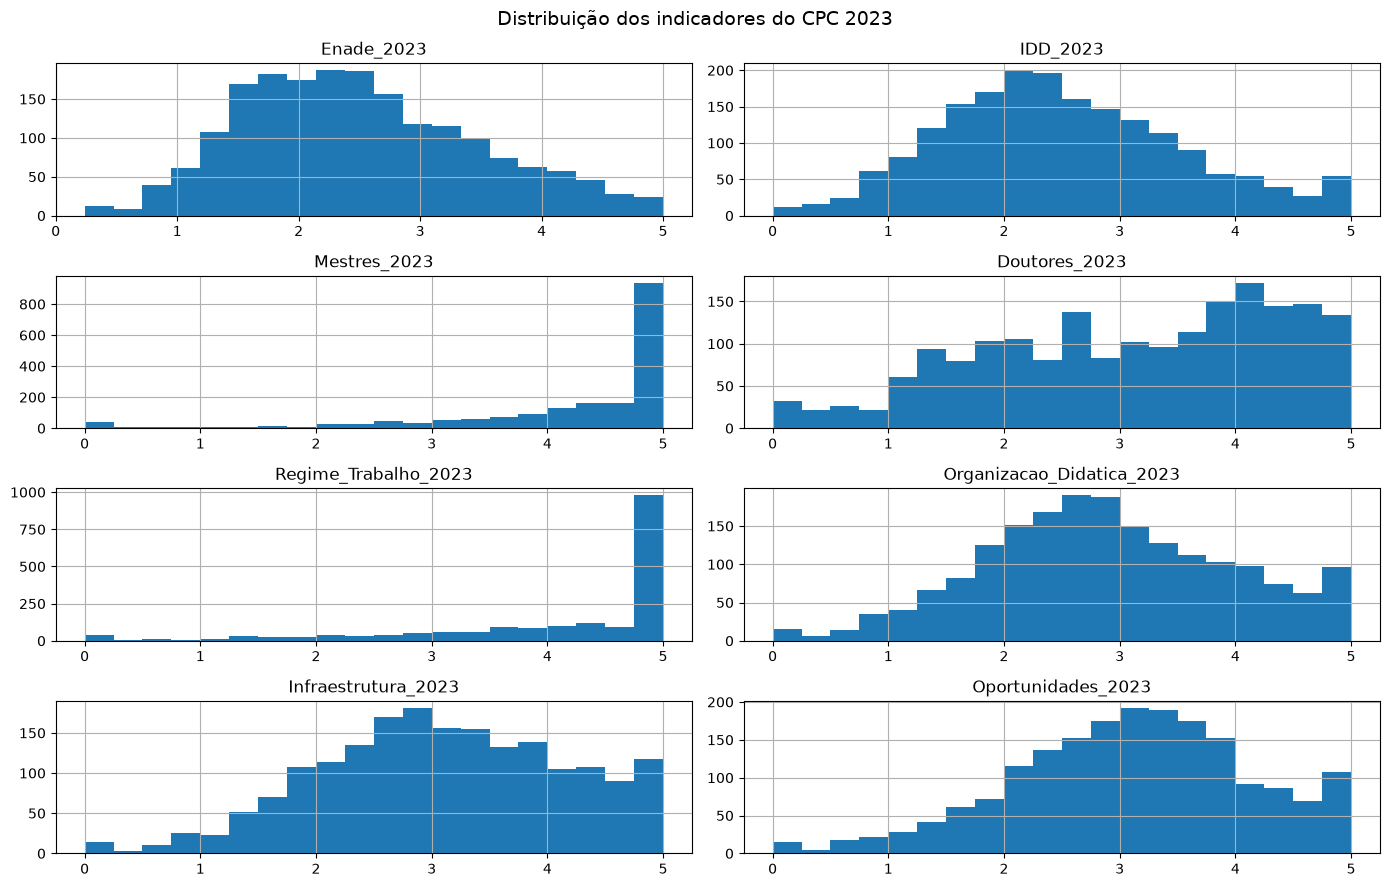

In [59]:

# Selecionar os oito indicadores de 2023
colunas_2023 = [
    f"{componente}_2023"
    for componente in componentes
]

# Visualizar as distribuições
df_analitica[colunas_2023].hist(
    bins=20,
    figsize=(14, 9),
    layout=(4, 2)
)

plt.suptitle(
    "Distribuição dos indicadores do CPC 2023",
    fontsize=14
)

plt.tight_layout()
plt.show()


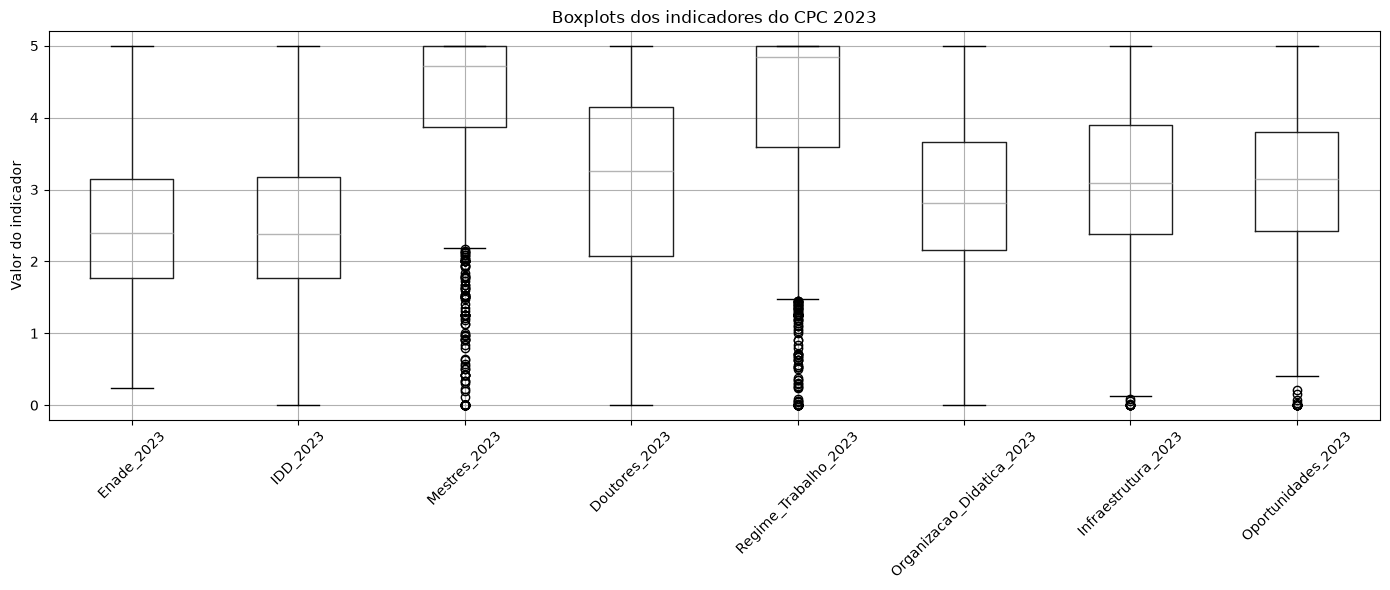

In [60]:

import matplotlib.pyplot as plt

# Boxplots dos oito indicadores de 2023
plt.figure(figsize=(14, 6))

df_analitica[colunas_2023].boxplot(
    rot=45
)

plt.title(
    "Boxplots dos indicadores do CPC 2023"
)

plt.ylabel("Valor do indicador")

plt.ylim(-0.2, 5.2)

plt.tight_layout()
plt.show()


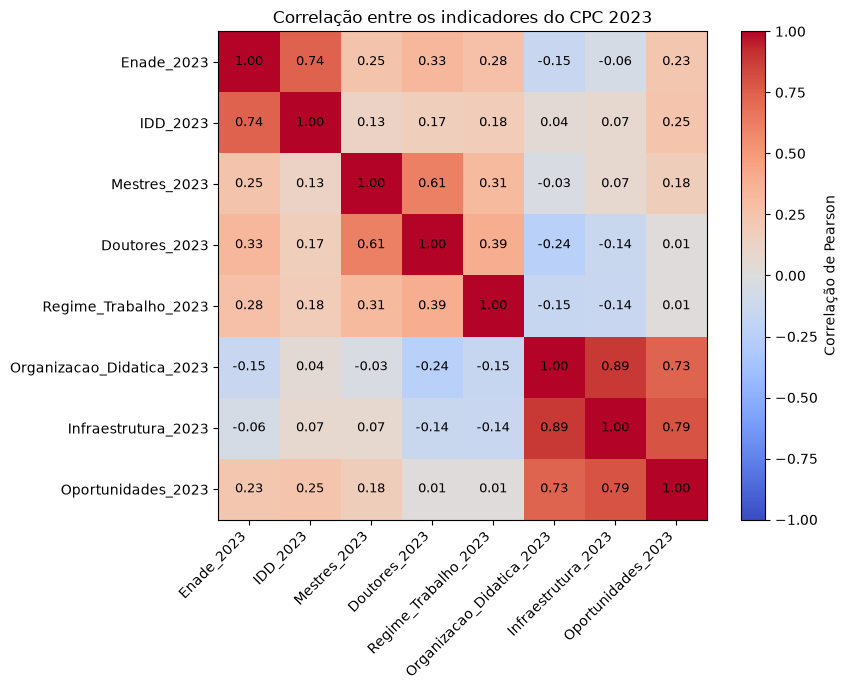

In [61]:

import matplotlib.pyplot as plt

# Calcular a matriz de correlação
correlacao = df_analitica[colunas_2023].corr()

# Visualizar a matriz
plt.figure(figsize=(9, 7))

plt.imshow(
    correlacao,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlação de Pearson")

plt.xticks(
    range(len(colunas_2023)),
    colunas_2023,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(colunas_2023)),
    colunas_2023
)

# Mostrar os valores das correlações
for i in range(len(colunas_2023)):
    for j in range(len(colunas_2023)):
        plt.text(
            j, i,
            f"{correlacao.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.title("Correlação entre os indicadores do CPC 2023")
plt.tight_layout()
plt.show()


In [62]:

# Calcular correlações por área de avaliação
resultados_correlacao = []

for area, grupo in df_analitica.groupby("Area_2023"):

    corr_organizacao = grupo[
        "Organizacao_Didatica_2023"
    ].corr(grupo["Infraestrutura_2023"])

    corr_desempenho = grupo[
        "Enade_2023"
    ].corr(grupo["IDD_2023"])

    resultados_correlacao.append({
        "Área": area,
        "Cursos": len(grupo),
        "Organização × Infraestrutura": corr_organizacao,
        "Enade × IDD": corr_desempenho
    })

df_correlacoes_areas = pd.DataFrame(
    resultados_correlacao
)

display(df_correlacoes_areas.round(3))


,Área,Cursos,Organização × Infraestrutura,Enade × IDD
0,21,266,0.897,0.729
1,5710,451,0.922,0.880
2,5806,234,0.920,0.729
3,5814,93,0.839,0.639
4,5902,245,0.911,0.783
5,6002,54,0.801,0.686
6,6008,107,0.883,0.700
7,6208,300,0.900,0.660
8,6307,109,0.802,0.634
9,6405,48,0.810,0.667


In [63]:
from pathlib import Path
import pandas as pd

# Pasta principal do projeto
pasta_projeto = Path(
    r"G:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026"
)

# Caminho da base de teste
caminho_teste = pasta_projeto / "dados" / "teste" / "base_teste_200_cursos.csv"

# Carregar os dados
df_teste = pd.read_csv(caminho_teste)

# Conferências iniciais
print("Dimensões da base:", df_teste.shape)
print("Quantidade de cursos da PUC-Rio:",
      (pd.to_numeric(df_teste["Código da IES"], errors="coerce") == 528).sum())

display(df_teste.head())

Dimensões da base: (200, 35)
Quantidade de cursos da PUC-Rio: 8


,Código da IES,Código do Curso,Modalidade_2017,Area_2017,Modalidade_2019,Area_2019,Modalidade_2023,Area_2023,CPC_2017,CPC_2019,...,Infraestrutura_2019,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2019,Oportunidades_2023
0,528,59962,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.6528,2.331,...,3.421,3.531,2.358,3.941,2.529,0.000,2.734,3.780,3.199,3.537
1,528,29445,Educação Presencial,5710,Educação Presencial,5710,Educação Presencial,5710,3.1808,3.047,...,3.686,3.930,3.827,4.315,4.130,2.464,2.934,3.837,3.094,3.807
2,528,29446,Educação Presencial,5806,Educação Presencial,5806,Educação Presencial,5806,3.5006,3.355,...,4.220,3.548,2.812,4.221,4.221,2.885,3.083,3.901,3.861,3.834
3,528,32655,Educação Presencial,5814,Educação Presencial,5814,Educação Presencial,5814,3.4575,3.070,...,3.659,2.766,1.784,4.413,4.014,2.840,1.356,3.772,3.478,3.735
4,528,23702,Educação Presencial,5902,Educação Presencial,5902,Educação Presencial,5902,3.1776,2.535,...,3.667,4.190,3.780,4.310,4.138,2.328,2.987,4.161,3.605,4.020


In [64]:
# Oito componentes do CPC
componentes = [
    "Enade",
    "IDD",
    "Mestres",
    "Doutores",
    "Regime_Trabalho",
    "Organizacao_Didatica",
    "Infraestrutura",
    "Oportunidades"
]

# Construir a lista dos 24 indicadores históricos
colunas_indicadores = [
    f"{componente}_{ano}"
    for ano in [2017, 2019, 2023]
    for componente in componentes
]

# Selecionar os registros completos
df_teste_completo = df_teste.dropna(
    subset=colunas_indicadores
).copy()

# Conferir o resultado
print("Cursos na base original de teste:", len(df_teste))
print("Cursos com indicadores completos:", len(df_teste_completo))
print("Cursos excluídos:", len(df_teste) - len(df_teste_completo))

print(
    "Cursos da PUC-Rio preservados:",
    (pd.to_numeric(
        df_teste_completo["Código da IES"],
        errors="coerce"
    ) == 528).sum()
)

print(
    "Valores ausentes nos 24 indicadores:",
    df_teste_completo[colunas_indicadores].isna().sum().sum()
)

Cursos na base original de teste: 200
Cursos com indicadores completos: 192
Cursos excluídos: 8
Cursos da PUC-Rio preservados: 8
Valores ausentes nos 24 indicadores: 0


In [65]:
# Selecionar os oito indicadores de 2023
colunas_2023 = [
    f"{componente}_2023"
    for componente in componentes
]

# Criar a matriz de dados do Cenário A
X_teste_A = df_teste_completo[colunas_2023].copy()

# Conferir as dimensões e os indicadores
print("Dimensões da matriz:", X_teste_A.shape)

print("\nIndicadores selecionados:")
for coluna in X_teste_A.columns:
    print("-", coluna)

print("\nEstatísticas descritivas:")
display(X_teste_A.describe().round(3))

Dimensões da matriz: (192, 8)

Indicadores selecionados:
- Enade_2023
- IDD_2023
- Mestres_2023
- Doutores_2023
- Regime_Trabalho_2023
- Organizacao_Didatica_2023
- Infraestrutura_2023
- Oportunidades_2023

Estatísticas descritivas:


,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023
count,192.000,192.000,192.000,192.000,192.000,192.000,192.000,192.000
mean,2.639,2.552,4.301,3.176,4.110,2.909,3.127,3.164
std,0.998,1.036,1.009,1.260,1.235,1.025,1.040,1.010
min,0.289,0.000,0.000,0.000,0.000,0.000,0.019,0.000
25%,1.876,1.784,4.058,2.247,3.414,2.194,2.406,2.517
50%,2.554,2.503,4.605,3.458,4.928,2.743,3.070,3.259
75%,3.342,3.190,5.000,4.143,5.000,3.639,3.940,3.798
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


In [66]:
import numpy as np

print("Todos os indicadores são numéricos:",
      all(pd.api.types.is_numeric_dtype(tipo)
          for tipo in X_teste_A.dtypes))

print("Existem valores ausentes:",
      X_teste_A.isna().any().any())

print("Todos os valores são finitos:",
      np.isfinite(X_teste_A.to_numpy()).all())

print("Todos os valores estão entre 0 e 5:",
      X_teste_A.between(0, 5).all().all())

print("Dimensões finais:", X_teste_A.shape)

Todos os indicadores são numéricos: True
Existem valores ausentes: False
Todos os valores são finitos: True


AttributeError: 'DataFrame' object has no attribute 'between'

In [67]:
import numpy as np

print("Todos os indicadores são numéricos:",
      all(pd.api.types.is_numeric_dtype(tipo)
          for tipo in X_teste_A.dtypes))

print("Existem valores ausentes:",
      X_teste_A.isna().any().any())

print("Todos os valores são finitos:",
      np.isfinite(X_teste_A.to_numpy()).all())

print("Todos os valores estão entre 0 e 5:",
      ((X_teste_A >= 0) & (X_teste_A <= 5)).all().all())

print("Dimensões finais:", X_teste_A.shape)

Todos os indicadores são numéricos: True
Existem valores ausentes: False
Todos os valores são finitos: True
Todos os valores estão entre 0 e 5: True
Dimensões finais: (192, 8)


In [69]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Quantidades de grupos que serão testadas
valores_k = range(2, 11)

inercias = []

# Executar K-means para cada quantidade de grupos
for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_teste_A)
    inercias.append(modelo.inertia_)

# Construir o gráfico do método do cotovelo
plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inercias, marker="o")

plt.xlabel("Número de agrupamentos (K)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — Cenário A (base de teste)")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

ModuleNotFoundError: No module named 'sklearn'

In [70]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----------------------- ---------------- 5.0/8.4 MB 24.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 21.9 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -------- ------------------------------- 8.1/37.4 MB 40.5 MB/s eta 0:00:01
   ------------------ --------------------- 17.0/37.4 MB 41.0 MB/s eta 0:00:01
   --------------------------- ------------ 25.7/37.4 MB 41.1 MB/s eta 0:00:01
   ------------------------------------ --- 34.1/37.4 MB 41.1 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 36.8 MB/s  0:00:01

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ----------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [71]:
from sklearn.cluster import KMeans

print("Scikit-learn importado com sucesso!")

Scikit-learn importado com sucesso!


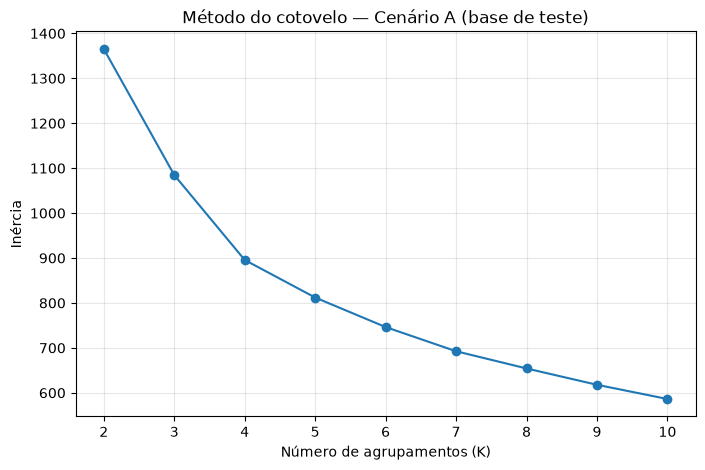

In [72]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Testar diferentes números de agrupamentos
valores_k = range(2, 11)

inercias = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_teste_A)
    inercias.append(modelo.inertia_)

# Gráfico do método do cotovelo
plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inercias, marker="o")

plt.xlabel("Número de agrupamentos (K)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — Cenário A (base de teste)")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)

plt.show()

In [73]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Testar os mesmos valores de K do método do cotovelo
resultados_silhueta = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    grupos = modelo.fit_predict(X_teste_A)

    silhueta = silhouette_score(X_teste_A, grupos)

    resultados_silhueta.append({
        "K": k,
        "Silhueta": silhueta
    })

# Organizar os resultados em uma tabela
df_silhueta = pd.DataFrame(resultados_silhueta)

display(df_silhueta.round(4))

,K,Silhueta
0,2,0.2236
1,3,0.2365
2,4,0.2437
3,5,0.2403
4,6,0.2046
5,7,0.2056
6,8,0.2121
7,9,0.2019
8,10,0.2000


In [74]:
# Executar K-means com quatro agrupamentos
modelo_kmeans_A = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Identificar o grupo de cada curso
grupos_A = modelo_kmeans_A.fit_predict(X_teste_A)

# Criar uma cópia dos dados com os grupos identificados
df_resultado_A = df_teste_completo.copy()

df_resultado_A["Grupo_KMeans_A"] = grupos_A

# Quantidade de cursos em cada grupo
print("Quantidade de cursos por grupo:")
display(
    df_resultado_A["Grupo_KMeans_A"]
    .value_counts()
    .sort_index()
    .rename_axis("Grupo")
    .reset_index(name="Quantidade de cursos")
)

# Conferir os cursos da PUC-Rio
print("\nGrupos dos cursos da PUC-Rio:")

display(
    df_resultado_A.loc[
        pd.to_numeric(
            df_resultado_A["Código da IES"],
            errors="coerce"
        ) == 528,
        ["Código do Curso", "Area_2023", "Grupo_KMeans_A"]
    ].sort_values("Area_2023")
)

Quantidade de cursos por grupo:


,Grupo,Quantidade de cursos
0,0,56
1,1,59
2,2,28
3,3,49



Grupos dos cursos da PUC-Rio:


,Código do Curso,Area_2023,Grupo_KMeans_A
0,59962,21,2
1,29445,5710,3
2,29446,5806,0
3,32655,5814,1
4,23702,5902,3
5,32975,6008,3
6,44431,6208,0
7,70523,6307,1


In [75]:
# Calcular as médias dos oito indicadores em cada grupo
perfil_grupos_A = (
    df_resultado_A
    .groupby("Grupo_KMeans_A")[colunas_2023]
    .mean()
    .round(3)
)

print("Perfil médio dos quatro grupos:")
display(perfil_grupos_A)

# Conferir a quantidade de cursos em cada grupo
print("\nQuantidade de cursos por grupo:")
display(
    df_resultado_A
    .groupby("Grupo_KMeans_A")
    .size()
    .rename("Quantidade de cursos")
)

Perfil médio dos quatro grupos:


,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023
Grupo_KMeans_A,,,,,,,,
0,2.450,2.713,4.581,2.934,4.271,4.013,4.298,4.195
1,2.037,1.736,4.490,3.496,4.193,2.362,2.503,2.379
2,2.070,2.107,2.576,1.269,2.447,3.017,2.993,2.799
3,3.906,3.606,4.739,4.155,4.776,2.244,2.616,3.140



Quantidade de cursos por grupo:


Grupo_KMeans_A
0    56
1    59
2    28
3    49
Name: Quantidade de cursos, dtype: int64

In [76]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Agrupamento hierárquico com quatro grupos
modelo_hierarquico_A = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward",
    metric="euclidean"
)

# Identificar os grupos
grupos_hierarquicos_A = modelo_hierarquico_A.fit_predict(X_teste_A)

# Calcular a silhueta
silhueta_hierarquico_A = silhouette_score(
    X_teste_A,
    grupos_hierarquicos_A
)

# Distribuição dos cursos
print("Quantidade de cursos por grupo:")
display(
    pd.Series(grupos_hierarquicos_A)
    .value_counts()
    .sort_index()
    .rename_axis("Grupo")
    .reset_index(name="Quantidade de cursos")
)

print(
    "\nSilhueta do agrupamento hierárquico:",
    round(silhueta_hierarquico_A, 4)
)

Quantidade de cursos por grupo:


,Grupo,Quantidade de cursos
0,0,104
1,1,25
2,2,33
3,3,30



Silhueta do agrupamento hierárquico: 0.18


In [77]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

resultados_hierarquico = []

for k in range(2, 11):

    modelo = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    grupos = modelo.fit_predict(X_teste_A)

    silhueta = silhouette_score(
        X_teste_A,
        grupos
    )

    resultados_hierarquico.append({
        "K": k,
        "Silhueta": silhueta
    })

df_silhueta_hierarquico = pd.DataFrame(
    resultados_hierarquico
)

print("Silhueta do agrupamento hierárquico por número de grupos:")
display(df_silhueta_hierarquico.round(4))

Silhueta do agrupamento hierárquico por número de grupos:


,K,Silhueta
0,2,0.2321
1,3,0.2068
2,4,0.1800
3,5,0.1707
4,6,0.1794
5,7,0.1817
6,8,0.1710
7,9,0.1765
8,10,0.1745


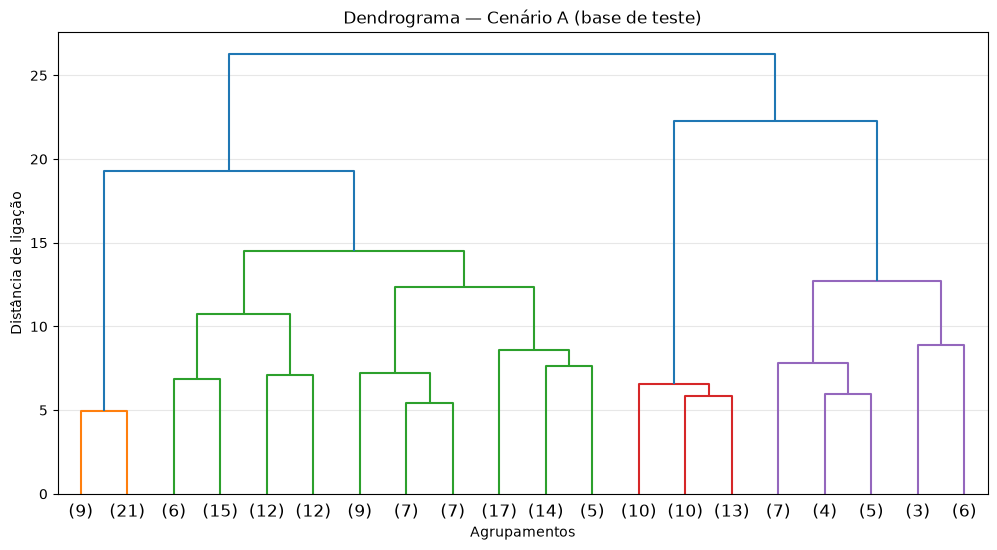

In [78]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Construir a hierarquia pelo método de Ward
matriz_ligacao_A = linkage(
    X_teste_A,
    method="ward",
    metric="euclidean"
)

# Exibir o dendrograma
plt.figure(figsize=(12, 6))

dendrogram(
    matriz_ligacao_A,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.title("Dendrograma — Cenário A (base de teste)")
plt.xlabel("Agrupamentos")
plt.ylabel("Distância de ligação")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [79]:
# Quantidade de cursos de cada área em cada grupo
tabela_areas_grupos = pd.crosstab(
    df_resultado_A["Area_2023"],
    df_resultado_A["Grupo_KMeans_A"]
)

print("Distribuição das áreas de avaliação nos grupos:")
display(tabela_areas_grupos)

# Percentuais dentro de cada área
tabela_percentuais = pd.crosstab(
    df_resultado_A["Area_2023"],
    df_resultado_A["Grupo_KMeans_A"],
    normalize="index"
) * 100

print("\nPercentual dos cursos de cada área em cada grupo:")
display(tabela_percentuais.round(1))

Distribuição das áreas de avaliação nos grupos:


Grupo_KMeans_A,0,1,2,3
Area_2023,,,,
21,10,6,6,5
5710,13,10,10,10
5806,8,5,1,8
5814,2,5,2,2
5902,3,10,3,10
6002,1,2,0,2
6008,5,4,0,3
6208,11,10,6,4
6307,2,4,0,5



Percentual dos cursos de cada área em cada grupo:


Grupo_KMeans_A,0,1,2,3
Area_2023,,,,
21,37.0,22.2,22.2,18.5
5710,30.2,23.3,23.3,23.3
5806,36.4,22.7,4.5,36.4
5814,18.2,45.5,18.2,18.2
5902,11.5,38.5,11.5,38.5
6002,20.0,40.0,0.0,40.0
6008,41.7,33.3,0.0,25.0
6208,35.5,32.3,19.4,12.9
6307,18.2,36.4,0.0,45.5
